<a href="https://colab.research.google.com/github/girish17work/Data-Analysis/blob/main/Unknown_Dataset_8/Unknown_Dataset_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [149]:
import pandas as pd
import numpy as np

In [150]:
DATASET_URL = 'https://drive.google.com/uc?export=download&id=1PSNwGlIMGTuK2YjZsvLQHdVjk6HzNEQT'
df = pd.read_csv(DATASET_URL)
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0


In [151]:
df.shape

(8128, 13)

In [152]:
df['transmission'].value_counts()

,count
transmission,
Manual,7078
Automatic,1050


<Axes: xlabel='selling_price', ylabel='Count'>

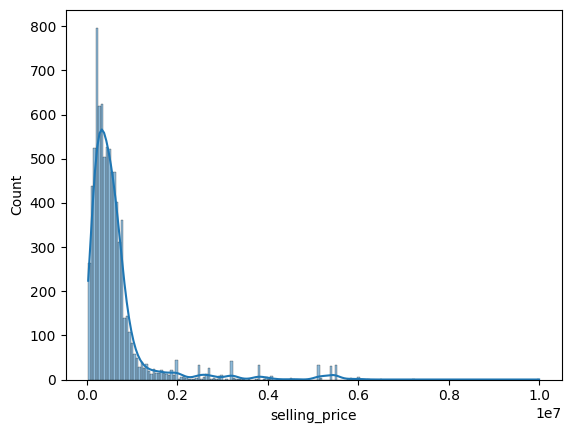

In [153]:
import seaborn as sns

sns.histplot(df['selling_price'], kde=True)

In [154]:
print(f'Percentage of diesel cars: {df['fuel'].value_counts(normalize=True)}')

Percentage of diesel cars: fuel
Diesel    0.541585
Petrol    0.446727
CNG       0.007013
LPG       0.004675
Name: proportion, dtype: float64


In [155]:
df[df['seats'] == df['seats'].max()]['name']

,name
4575,Tata Winger Deluxe - Flat Roof (Non-AC)


In [156]:
df.groupby('year')['selling_price'].mean().idxmax()

np.int64(2019)

In [157]:
((df['seller_type']=='Individual') & (df['fuel']=='Diesel') & (df['owner']=='Second Owner')).sum()

np.int64(1124)

In [158]:
df[df['year'] == df['year'].min()]['selling_price']

,selling_price
316,300000


In [159]:
def first_word(s):
  return str(s).split(' ')[0]

df['name'] = df['name'].apply(first_word).astype(str)
df['mileage'] = df['mileage'].apply(first_word).astype(float)
df['engine'] = df['engine'].apply(first_word).astype(float)
df['max_power'] = pd.to_numeric(df['max_power'].apply(first_word), errors='coerce')

In [160]:
df.shape

(8128, 13)

In [161]:
df['max_power'].mean()

np.float64(91.51791898382203)

In [162]:
((df['name']=='Tata') & (df['max_power']>df['max_power'].mean()) & (df['mileage']>20)).sum()

np.int64(19)

In [163]:
import datetime

df['age'] = datetime.datetime.now().year - df['year']

In [164]:
df = df.drop(columns=['year', 'torque'])

In [165]:
df.shape

(8128, 12)

<Axes: >

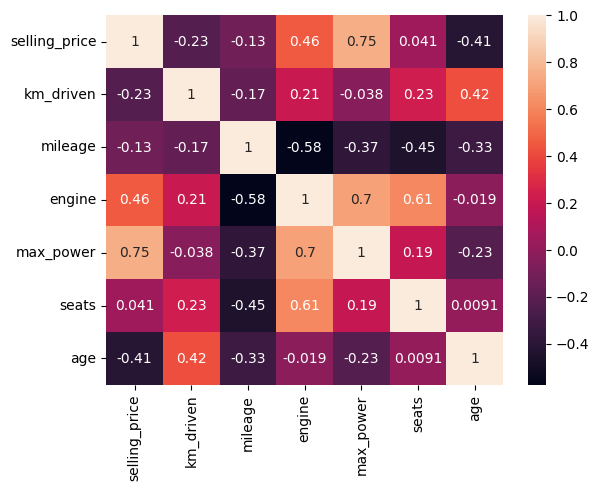

In [166]:
sns.heatmap(df.corr(numeric_only=True), annot=True)

In [167]:
corr = df.corr(numeric_only=True)
print(abs(corr[corr != 1]).max().max())

0.7484887482950324


In [168]:
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split

X = df.drop(columns=['selling_price'])
y = df['selling_price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

preprocessor = ColumnTransformer([
    ('freq', SimpleImputer(strategy='most_frequent'), ['seats']),
    ('mean', SimpleImputer(strategy='mean'), ['mileage', 'max_power']),
    ('med', SimpleImputer(strategy='median'), ['engine'])
], remainder='passthrough', verbose_feature_names_out=False).set_output(transform='pandas')

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

In [169]:
X_test.isna().sum().sort_values(ascending=False)

,0
seats,0
mileage,0
max_power,0
engine,0
name,0
km_driven,0
fuel,0
seller_type,0
transmission,0
owner,0


<Axes: xlabel='max_power', ylabel='Count'>

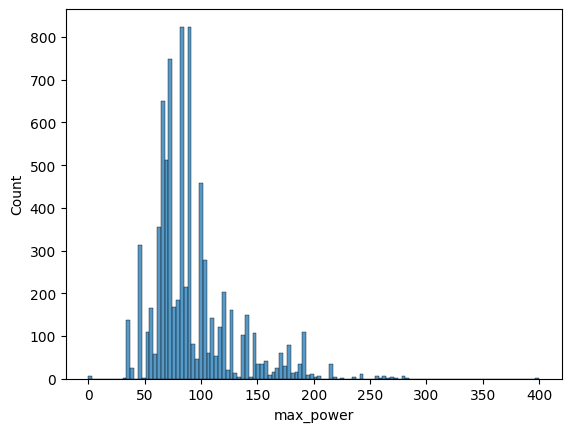

In [170]:
sns.histplot(df['max_power'])

In [171]:
print(f'Median of the engine columns: {df['engine'].median()}')

Median of the engine columns: 1248.0


In [172]:
print(f'Most frequent value of the seats column: {df['seats'].mode()[0]}')

Most frequent value of the seats column: 5.0


In [175]:
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

owner_categories = ['First Owner', 'Second Owner', 'Third Owner', 'Fourth & Above Owner', 'Test Drive Car']

ct = ColumnTransformer([
    ('ode', OrdinalEncoder(), ['name']),
    ('odec', OrdinalEncoder(categories=[owner_categories]), ['owner']),
    ('nom', OneHotEncoder(sparse_output=False, drop='first'), ['fuel', 'seller_type', 'transmission'])
], remainder='passthrough', verbose_feature_names_out=False).set_output(transform='pandas')

pipeline = Pipeline([
    ('ct', ct),
    ('scale', StandardScaler())
]).set_output(transform='pandas')

X_train = pipeline.fit_transform(X_train)
X_test = pipeline.transform(X_test)

In [176]:
print(X_train.shape)

(6502, 14)


In [177]:
print(X_test.to_numpy().sum())

-170.70408879426395


In [179]:
print(f'Number of features in the transformed test dataset: {X_test.shape[1]}')

Number of features in the transformed test dataset: 14


In [185]:
from sklearn.utils import shuffle

X = pd.concat([X_train, X_test], axis=0)
y = pd.concat([y_train, y_test], axis=0)
X = X.reset_index(drop=True)
y = y.reset_index(drop=True)
merged_df = pd.concat([X, y], axis=1)
shuffle_sf = shuffle(merged_df, random_state=42).reset_index(drop=True)

In [186]:
DATASET_URL = 'https://drive.google.com/uc?export=download&id=1SyC7enE_cFEiqGSirdF7dZscHVceFgBH'
df = pd.read_csv(DATASET_URL)
df.head()

,name,owner,fuel_Diesel,fuel_LPG,fuel_Petrol,seller_type_Individual,seller_type_Trustmark Dealer,transmission_Manual,mileage,max_power,engine,seats,km_driven,age,selling_price
0,1.627754,4.913939,0.913309,-0.069214,-0.891707,-2.264549,-0.171607,0.383063,0.720692,0.481642,0.086454,-0.426905,-1.107923,-1.279377,1350000
1,0.268837,-0.638071,0.913309,-0.069214,-0.891707,0.441589,-0.171607,0.383063,2.264354,-0.496293,-0.415360,-0.426905,-0.343614,-1.033471,650000
2,0.268837,-0.638071,-1.094920,-0.069214,1.121445,0.441589,-0.171607,0.383063,-0.127943,-0.691993,-0.917174,-0.426905,0.855976,0.687871,195000
3,1.084187,-0.638071,-1.094920,-0.069214,1.121445,0.441589,-0.171607,0.383063,0.907040,-0.694821,-0.915167,-0.426905,0.341866,-1.279377,220000
4,-1.905431,-0.638071,-1.094920,-0.069214,1.121445,0.441589,-0.171607,0.383063,-0.304218,-0.259304,-0.513716,-0.426905,-0.343614,-0.295753,200000


In [191]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

X = df.drop(columns=['selling_price'])
y = df['selling_price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

ridge = Ridge(alpha=1, solver='saga', tol=1e-2, random_state=42, max_iter=500)
ridge.fit(X_train, y_train)

y_pred = ridge.predict(X_test)
print(f'R2 score on the Test Dataset: {r2_score(y_test, y_pred)}')

R2 score on the Test Dataset: 0.6995872404455848


In [193]:
print(f'Most important feature: {np.argmax(ridge.coef_)}')

Most important feature: 9


In [194]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import GridSearchCV

estimator = DecisionTreeRegressor(criterion='absolute_error', random_state=42)
param_grid = {
    'max_depth': [10, 15, 20],
    'min_samples_split': [5, 10, 15],
    'max_features': ['sqrt', 'log2']
}
grid_search_cv = GridSearchCV(estimator=estimator, param_grid=param_grid, cv=5, scoring='neg_mean_absolute_error', n_jobs=-1)
grid_search_cv.fit(X_train, y_train)

GridSearchCV(cv=5,
             estimator=DecisionTreeRegressor(criterion='absolute_error',
                                             random_state=42),
             n_jobs=-1,
             param_grid={'max_depth': [10, 15, 20],
                         'max_features': ['sqrt', 'log2'],
                         'min_samples_split': [5, 10, 15]},
             scoring='neg_mean_absolute_error')

In [196]:
print(f'Max Depth: {grid_search_cv.best_params_['max_depth']}')

Max Depth: 20


In [197]:
from sklearn.metrics import r2_score

best_estimator = grid_search_cv.best_estimator_
y_pred = best_estimator.predict(X_test)

print(f'R2 score: {round(r2_score(y_test, y_pred), 3)}')

R2 score: 0.887


In [198]:
print(f'Height of the best tree: {best_estimator.get_depth()}')

Height of the best tree: 20


In [201]:
print(f'Node count: {best_estimator.tree_.node_count}')

Node count: 4257


In [202]:
from sklearn.svm import SVR

svr = SVR(kernel='poly', degree=3, C=0.1)
svr.fit(X_train, y_train)

SVR(C=0.1, kernel='poly')

In [203]:
from sklearn.metrics import root_mean_squared_error

y_pred = svr.predict(X_test)
print(f'Root Mean Squared Error: {round(root_mean_squared_error(y_test, y_pred), 3)}')

Root Mean Squared Error: 902236.541


In [207]:
print(f'Number of support vectors: {svr.support_vectors_.shape[0]}')

Number of support vectors: 6498


In [208]:
from sklearn.linear_model import SGDRegressor
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

pipeline = Pipeline([('pca', PCA()), ('sgd', SGDRegressor(random_state=42))])
param_grid = {
    'pca__n_components': [0.8, 0.9],
    'sgd__max_iter': [500, 1000, 1500],
    'sgd__eta0': [0.01, 0.1, 10]
}
grid_search_cv = GridSearchCV(pipeline, param_grid=param_grid, cv=5, n_jobs=-1, scoring='neg_root_mean_squared_error')
grid_search_cv.fit(X_train, y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('pca', PCA()),
                                       ('sgd', SGDRegressor(random_state=42))]),
             n_jobs=-1,
             param_grid={'pca__n_components': [0.8, 0.9],
                         'sgd__eta0': [0.01, 0.1, 10],
                         'sgd__max_iter': [500, 1000, 1500]},
             scoring='neg_root_mean_squared_error')

In [212]:
print(f'Number of iterations on the best pipeline: {grid_search_cv.best_estimator_.named_steps['sgd'].n_iter_}')

Number of iterations on the best pipeline: 15


In [214]:
print(f'Variance along the first principal component: {grid_search_cv.best_estimator_.named_steps['pca'].explained_variance_[0]}')

Variance along the first principal component: 3.26318886262726


In [217]:
from sklearn.feature_selection import SelectKBest, f_regression

k_best = SelectKBest(f_regression, k=5)
k_best.fit(X_train, y_train)

print(f'Sum of scores of the top 5 scores: {sum(sorted(k_best.scores_, reverse=True)[:5])}')

Sum of scores of the top 5 scores: 15184.297782968477
